# Arabic Sentiment Analysis — MARBERT Fine-Tuning

Fine-tuning MARBERT for three-class Arabic sentiment classification. This notebook includes training, validation, final held-out test evaluation, and an interactive Gradio demo.

## 1. Environment Setup

In [ ]:

# Install the libraries needed for transformer fine-tuning.
!pip -q install "transformers>=4.50,<5" "datasets>=3,<5" \
    "accelerate>=1,<2" scikit-learn pandas


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 92.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 48.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 72.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [ ]:

import pandas as pd
import numpy as np
import torch

from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)

from sklearn.metrics import accuracy_score, f1_score
from sklearn.metrics import classification_report

# Check whether a GPU is available.
print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


## 2. Load the Finalized Dataset

In [ ]:

from google.colab import files

# Upload the three CSV files saved in Part 1.
uploaded = files.upload()


Saving test.csv to test.csv
Saving train.csv to train.csv
Saving validation.csv to validation.csv


In [ ]:

# I reuse the same dataset splits as my baseline model.
train_df = pd.read_csv("train.csv")
val_df = pd.read_csv("validation.csv")
test_df = pd.read_csv("test.csv")

print("Training examples:", len(train_df))
print("Validation examples:", len(val_df))
print("Testing examples:", len(test_df))

display(train_df.head())


Training examples: 14752
Validation examples: 1844
Testing examples: 1845


,text,sentiment
0,مشاهدة مباراة مصر وغانا بث مباشر تصفيات كأس ال...,Neutral
1,يجيك واحد ويقولك ان انا مع الجيش لكن ضد حفتر و...,Positive
2,انطلقت شرارة موامرة الربيع العربي (العبري) من ...,Negative
3,"تصفيات كاس العالم "" أفريقيا "" تونس ( 0 ) × ليب...",Neutral
4,"بشار الأسد""ضعف الشعورالقومي وسوء أداء الحكومات...",Negative


## 3. Prepare Sentiment Labels

In [ ]:
# Map sentiment categories to numerical IDs.
label2id = {
    "Negative": 0,
    "Neutral": 1,
    "Positive": 2
}

id2label = {
    0: "Negative",
    1: "Neutral",
    2: "Positive"
}

for dataframe in [train_df, val_df, test_df]:
    dataframe["text"] = dataframe["text"].fillna("").astype(str)
    dataframe["labels"] = dataframe["sentiment"].map(label2id)

    # Check that every sentiment was mapped.
    assert dataframe["labels"].notna().all()

    dataframe["labels"] = dataframe["labels"].astype(int)

print(train_df[["text", "sentiment", "labels"]].head())

                                                text sentiment  labels
0  مشاهدة مباراة مصر وغانا بث مباشر تصفيات كأس ال...   Neutral       1
1  يجيك واحد ويقولك ان انا مع الجيش لكن ضد حفتر و...  Positive       2
2  انطلقت شرارة موامرة الربيع العربي (العبري) من ...  Negative       0
3  تصفيات كاس العالم " أفريقيا " تونس ( 0 ) × ليب...   Neutral       1
4  بشار الأسد"ضعف الشعورالقومي وسوء أداء الحكومات...  Negative       0


## 4. Convert Data into Hugging Face Format

In [ ]:

# Convert pandas tables into Hugging Face datasets.
train_dataset = Dataset.from_pandas(
    train_df[["text", "labels"]],
    preserve_index=False
)

val_dataset = Dataset.from_pandas(
    val_df[["text", "labels"]],
    preserve_index=False
)

print(train_dataset)
print(val_dataset)


Dataset({
    features: ['text', 'labels'],
    num_rows: 14752
})
Dataset({
    features: ['text', 'labels'],
    num_rows: 1844
})


## 5. Load MARBERT and tokenize Arabic text

In [ ]:

MODEL_NAME = "UBC-NLP/MARBERT"

# Load MARBERT's pretrained tokenizer.
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Convert Arabic sentences into model inputs.
def tokenize_text(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=128
    )

train_tokenized = train_dataset.map(
    tokenize_text,
    batched=True
)

val_tokenized = val_dataset.map(
    tokenize_text,
    batched=True
)

print("Tokenization completed!")


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/376 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/701 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Map:   0%|          | 0/14752 [00:00<?, ? examples/s]

Map:   0%|          | 0/1844 [00:00<?, ? examples/s]

Tokenization completed!


In [ ]:

# Load pretrained MARBERT with a 3-class classification head.
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    label2id=label2id,
    id2label=id2label
)

print("MARBERT loaded successfully!")


pytorch_model.bin:   0%|          | 0.00/654M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at UBC-NLP/MARBERT and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


MARBERT loaded successfully!


## 6. Define Evaluation Metrics

In [ ]:

def compute_metrics(eval_prediction):
    logits, labels = eval_prediction

    # Select the highest-scoring sentiment category.
    predictions = np.argmax(logits, axis=-1)

    accuracy = accuracy_score(labels, predictions)

    macro_f1 = f1_score(
        labels,
        predictions,
        average="macro"
    )

    return {
        "accuracy": accuracy,
        "macro_f1": macro_f1
    }

print("Evaluation metrics ready!")


Evaluation metrics ready!


## 7. Fine-Tune MARBERT

In [ ]:

# I start with a smaller training experiment to check
# that the model and training pipeline work correctly.
pilot_train = train_tokenized.select(
    range(min(1500, len(train_tokenized)))
)

pilot_val = val_tokenized.select(
    range(min(400, len(val_tokenized)))
)

# Dynamically pad sentences within each batch.
data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

print("Pilot training examples:", len(pilot_train))
print("Pilot validation examples:", len(pilot_val))


Pilot training examples: 1500
Pilot validation examples: 400


In [ ]:

# Configure a short initial fine-tuning experiment.
training_args = TrainingArguments(
    output_dir="./marbert_pilot",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=2,
    num_train_epochs=1,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="no",
    logging_steps=25,
    report_to="none",
    fp16=torch.cuda.is_available(),
    seed=42
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=pilot_train,
    eval_dataset=pilot_val,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

print("Training configuration ready!")


Training configuration ready!


In [ ]:

# Start the pilot fine-tuning experiment.
trainer.train()

# Evaluate on the pilot validation subset.
pilot_results = trainer.evaluate()

print("Pilot results:", pilot_results)


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.525100,0.489506,0.820000,0.798382


Pilot results: {'eval_loss': 0.4895060658454895, 'eval_accuracy': 0.82, 'eval_macro_f1': 0.7983817150483817, 'eval_runtime': 1.3542, 'eval_samples_per_second': 295.374, 'eval_steps_per_second': 36.922, 'epoch': 1.0}


## 8. Full Fine-Tuning Experiment

In [ ]:

# Restart from the pretrained MARBERT weights.
model_full = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    label2id=label2id,
    id2label=id2label
)

full_args = TrainingArguments(
    output_dir="./marbert_full",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=2,
    num_train_epochs=2,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=1,
    logging_steps=50,
    report_to="none",
    fp16=torch.cuda.is_available(),
    seed=42
)

full_trainer = Trainer(
    model=model_full,
    args=full_args,
    train_dataset=train_tokenized,
    eval_dataset=val_tokenized,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

full_trainer.train()

full_results = full_trainer.evaluate()

print("Full validation results:", full_results)


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at UBC-NLP/MARBERT and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.429200,0.379698,0.849783,0.837697
2,0.250600,0.461749,0.845987,0.834972


Full validation results: {'eval_loss': 0.37969765067100525, 'eval_accuracy': 0.8497830802603037, 'eval_macro_f1': 0.83769709123759, 'eval_runtime': 3.6068, 'eval_samples_per_second': 511.257, 'eval_steps_per_second': 64.046, 'epoch': 2.0}


## 9. Save Fine-Tuned MARBERT

In [ ]:

# Save my fine-tuned model and tokenizer.
SAVE_PATH = "./marbert_sentiment_model"

full_trainer.save_model(SAVE_PATH)
tokenizer.save_pretrained(SAVE_PATH)

print("Fine-tuned MARBERT saved!")


Fine-tuned MARBERT saved!


In [ ]:

from google.colab import drive
import shutil

drive.mount("/content/drive")

destination = (
    "/content/drive/MyDrive/"
    "Arabic_Sentiment_Analysis/marbert_sentiment_model"
)

shutil.copytree(
    SAVE_PATH,
    destination,
    dirs_exist_ok=True
)

print("Model backed up to Google Drive!")


Mounted at /content/drive
Model backed up to Google Drive!


## 10. Test Arabic Sentences

In [ ]:

# Predict sentiment using my fine-tuned transformer.
def predict_marbert(text):
    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=128
    )

    # Move inputs to the same device as the model.
    inputs = {
        key: value.to(full_trainer.model.device)
        for key, value in inputs.items()
    }

    full_trainer.model.eval()

    with torch.no_grad():
        outputs = full_trainer.model(**inputs)

    predicted_id = outputs.logits.argmax(dim=-1).item()
    return id2label[predicted_id]


examples = [
    "التطبيق ممتاز وسهل الاستخدام",
    "الخدمة سيئة جدا وما عجبتني",
    "تم تحديث التطبيق اليوم",
    "الصراحة التجربة كانت رهيبة",
    "الخدمة مو ممتازة أبدا"
]

for sentence in examples:
    print(sentence)
    print("Prediction:", predict_marbert(sentence))
    print("-" * 40)


التطبيق ممتاز وسهل الاستخدام
Prediction: Positive
----------------------------------------
الخدمة سيئة جدا وما عجبتني
Prediction: Negative
----------------------------------------
تم تحديث التطبيق اليوم
Prediction: Neutral
----------------------------------------
الصراحة التجربة كانت رهيبة
Prediction: Positive
----------------------------------------
الخدمة مو ممتازة أبدا
Prediction: Negative
----------------------------------------


In [ ]:

import numpy as np
from sklearn.metrics import classification_report

# I evaluate MARBERT on my existing validation dataset.
val_output = full_trainer.predict(val_tokenized)

predicted_labels = np.argmax(
    val_output.predictions,
    axis=-1
)

print(classification_report(
    val_output.label_ids,
    predicted_labels,
    labels=[0, 1, 2],
    target_names=["Negative", "Neutral", "Positive"],
    digits=4
))


              precision    recall  f1-score   support

    Negative     0.8735    0.8878    0.8806       731
     Neutral     0.8469    0.8881    0.8670       679
    Positive     0.8098    0.7258    0.7655       434

    accuracy                         0.8498      1844
   macro avg     0.8434    0.8339    0.8377      1844
weighted avg     0.8487    0.8498    0.8485      1844



## 11. Final Test Set Evaluation

Map:   0%|          | 0/1845 [00:00<?, ? examples/s]

Final Test Accuracy: 83.58%
Final Test Macro-F1: 0.8248
              precision    recall  f1-score   support

    Negative     0.8706    0.8837    0.8771       731
     Neutral     0.8236    0.8527    0.8379       679
    Positive     0.7925    0.7287    0.7593       435

    accuracy                         0.8358      1845
   macro avg     0.8289    0.8217    0.8248      1845
weighted avg     0.8349    0.8358    0.8349      1845



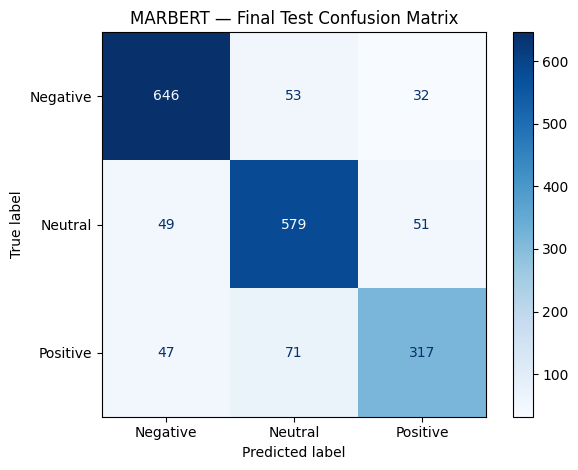

In [ ]:

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import numpy as np

# I evaluate my selected MARBERT model on the
# untouched held-out test dataset.
test_dataset = Dataset.from_pandas(
    test_df[["text", "labels"]],
    preserve_index=False
)

test_tokenized = test_dataset.map(
    tokenize_text,
    batched=True
)

test_output = full_trainer.predict(test_tokenized)

test_predictions = np.argmax(
    test_output.predictions,
    axis=-1
)

# Calculate final test metrics.
test_accuracy = accuracy_score(
    test_output.label_ids,
    test_predictions
)

test_macro_f1 = f1_score(
    test_output.label_ids,
    test_predictions,
    average="macro"
)

print(f"Final Test Accuracy: {test_accuracy:.2%}")
print(f"Final Test Macro-F1: {test_macro_f1:.4f}")

print(classification_report(
    test_output.label_ids,
    test_predictions,
    labels=[0, 1, 2],
    target_names=["Negative", "Neutral", "Positive"],
    digits=4
))

# Display the final confusion matrix.
ConfusionMatrixDisplay.from_predictions(
    test_output.label_ids,
    test_predictions,
    display_labels=["Negative", "Neutral", "Positive"],
    cmap="Blues"
)

plt.title("MARBERT — Final Test Confusion Matrix")
plt.tight_layout()
plt.show()


## 12. Interactive Gradio Demo

This section loads my **previously fine-tuned** MARBERT model and launches a sentiment prediction interface. **Training is not required to run the demo.** The model must be saved either in the current Colab runtime (`./marbert_sentiment_model`) or in my Google Drive backup (`MyDrive/Arabic_Sentiment_Analysis/marbert_sentiment_model`).

**After reconnecting to Colab:** Run only the four code cells in this section, in order. If I install or change packages, I restart the session once, then run the *import check*, *load*, *predict*, and *launch* cells. If the first cell already works, I do not need to reinstall packages.

In [5]:
# Install compatible packages for the demo if needed.
# After installation, restart the runtime only if imports fail or Colab requests it.
%pip uninstall -y transformers huggingface-hub tokenizers
%pip install --no-cache-dir "transformers==4.57.6" "huggingface-hub==0.36.2" "gradio>=5,<7"

import gradio as gr
import huggingface_hub
print("Gradio:", gr.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)

Found existing installation: transformers 4.57.6
Uninstalling transformers-4.57.6:
  Successfully uninstalled transformers-4.57.6
Found existing installation: huggingface_hub 0.36.2
Uninstalling huggingface_hub-0.36.2:
  Successfully uninstalled huggingface_hub-0.36.2
Found existing installation: tokenizers 0.22.2
Uninstalling tokenizers-0.22.2:
  Successfully uninstalled tokenizers-0.22.2
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 9.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 265.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 428.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 262.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible

In [1]:

import torch
import transformers
import huggingface_hub
import gradio as gr

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

print("Transformers:", transformers.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)
print("Gradio:", gr.__version__)

print("All libraries imported successfully!")


Transformers: 4.57.6
Hugging Face Hub: 0.36.2
Gradio: 6.17.3
All libraries imported successfully!


In [2]:
from pathlib import Path
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# First try the saved folder in this runtime; otherwise use my Drive backup.
local_path = Path("/content/marbert_sentiment_model")
drive_path = Path("/content/drive/MyDrive/Arabic_Sentiment_Analysis/marbert_sentiment_model")

if (local_path / "config.json").exists():
    model_path = local_path
else:
    from google.colab import drive
    drive.mount("/content/drive")
    model_path = drive_path

if not (model_path / "config.json").exists():
    raise FileNotFoundError(
        "Saved MARBERT model not found. Check the model backup in Google Drive "
        "and update drive_path if its folder name differs. Do not retrain."
    )

tokenizer_demo = AutoTokenizer.from_pretrained(str(model_path))
model_demo = AutoModelForSequenceClassification.from_pretrained(str(model_path))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_demo.to(device)
model_demo.eval()
print("Loaded fine-tuned model from:", model_path)
print("Device:", device)

Mounted at /content/drive
Loaded fine-tuned model from: /content/drive/MyDrive/Arabic_Sentiment_Analysis/marbert_sentiment_model
Device: cuda


In [3]:
def predict_sentiment_gradio(text):
    # Return no prediction for empty text.
    if not text or not text.strip():
        return {}

    # Convert text into the token IDs MARBERT expects.
    inputs = tokenizer_demo(
        text, return_tensors="pt", truncation=True, max_length=128
    )
    inputs = {name: value.to(device) for name, value in inputs.items()}

    # Predict without modifying the trained model.
    with torch.no_grad():
        logits = model_demo(**inputs).logits
        probabilities = torch.softmax(logits, dim=-1)[0].cpu().tolist()

    return {
        model_demo.config.id2label[i]: float(score)
        for i, score in enumerate(probabilities)
    }

# Check the prediction function before launching Gradio.
print(predict_sentiment_gradio("الصراحة التجربة كانت رهيبة"))

{'Negative': 0.06510649621486664, 'Neutral': 0.033452484756708145, 'Positive': 0.9014410972595215}


In [4]:
# Build and launch the interactive Arabic sentiment demo.
demo = gr.Interface(
    fn=predict_sentiment_gradio,
    inputs=gr.Textbox(
        lines=3,
        placeholder="اكتب جملة باللغة العربية هنا...",
        label="Arabic Text | النص العربي"
    ),
    outputs=gr.Label(
        num_top_classes=3,
        label="Sentiment Prediction | تحليل المشاعر"
    ),
    title="Arabic Sentiment Analyzer | محلل المشاعر العربية",
    description=(
        "A three-class Arabic sentiment classifier fine-tuned from MARBERT. "
        "Enter Arabic text to view predictions for Positive, Neutral and Negative."
    ),
    examples=[
        ["التطبيق ممتاز وسهل الاستخدام"],
        ["الخدمة سيئة جدا وما عجبتني"],
        ["تم تحديث التطبيق اليوم"],
        ["الصراحة التجربة كانت رهيبة"],
        ["الخدمة مو ممتازة أبدا"]
    ],
    flagging_mode="never"
)

demo.launch(share=True)  # Temporary share link; not a permanent deployment.


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://637b2af24a507a3bda.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
